# Lab 3 — Millions of TVs, Who Is Watching?
Name: Volkov Oleksii | Group: KM-42

## Setup

In [ ]:
import re
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

In [ ]:
# --- helpers and prepared tables (the lab's rules live here) ---
P0, P1 = pd.Timestamp("2024-10-14"), pd.Timestamp("2024-10-27")   # the two broadcast weeks
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]                          # the "big" five networks of the dataset README
pd.set_option("display.width", 250, "display.max_columns", 30)


def eastern(s, utc=False):
    """Timestamps -> naive US Eastern (utc=True: naive values are UTC)."""
    s = pd.to_datetime(s, utc=utc)
    return s if s.dt.tz is None else s.dt.tz_convert("America/New_York").dt.tz_localize(None)


def prep(df, start, end, utc=False):
    """Add t0, t1 (Eastern), hours, and bd = broadcast day (06:00-05:59) of the start."""
    df = df.assign(t0=eastern(df[start], utc), t1=eastern(df[end], utc))
    return df.assign(hours=(df.t1 - df.t0).dt.total_seconds() / 3600,
                     bd=(df.t0 - pd.Timedelta(hours=6)).dt.normalize())


def watchers(sess, t, key):
    """Ids (key) whose sessions on telecast t's network overlap it by >= 1 minute in total."""
    s = sess[sess.network_code == t.network_code]
    sec = (s.t1.clip(upper=t.t1) - s.t0.clip(lower=t.t0)).dt.total_seconds().clip(lower=0)
    sec = sec.groupby(s[key]).sum()
    return sec.index[sec >= 60]


programs = prep(programs, "start_ts", "end_ts").assign(bd=lambda d: pd.to_datetime(d.broadcast_date))
TEN = sorted(programs.network_code.unique())

acr = prep(acr_sessions, "start_utc", "end_utc", utc=True)     # time rule: UTC -> Eastern
ed = acr[acr.t1 - acr.t0 >= pd.Timedelta(minutes=1)]           # edit rule
live = ed[ed.session_type == "live"]                           # only live counts as viewing a network
intab = ed.groupby("bd").tv_id.nunique()                       # TVs in-tab per broadcast day

pan = prep(viewings, "start_ts", "end_ts")                     # panel sessions
pan = pan[pan.bd.between(P0, P1)]
dw = daily_weights.assign(bd=pd.to_datetime(daily_weights.broadcast_date))
dw = dw[dw.bd.between(P0, P1)]                                 # panel in-tab days, two weeks
dwH = dw[dw.resp_type == "H"]
panH = pan[pan.resp_type == "H"]

## Task 1.1 — Five questions
**Answer:** the table (acr_sessions vs Lab 1 viewings) and the biggest difference.

| | `acr_sessions` | Lab 1 `viewings` |
|---|---|---|
| **Grain** | one TV showing one thing without a break | one person (or the household's set) on one network without a break |
| **Key** | `session_id`; device `tv_id`; home only via `hashed_ip` | `viewing_id`; `respondent_id` = household + person number |
| **Coverage** | 29,940 opted-in smart TVs of one brand, one per home, Oct 14–27 2024; any network, plus apps and unrecognised time | recruited US panel, every set in the home, October 2024; ten networks, live only |
| **Weight** | none: every TV counts once | daily weight per household (sums to 125.8M US TV households) and per person (317.3M US persons) |
| **Provenance** | passive ACR fingerprinting after opt-in; demographics from a compiled/modeled file joined by IP | people meters; demographics reported by the households themselves |

The biggest difference is **coverage**, and the missing **weight** follows from it. The panel is a designed sample of all US TV homes,
weighted to stand for every one of them;
the feed is an unweighted convenience sample of whoever bought the TV and opted in, so its size says nothing about whom it represents.

## Task 1.2 — Size and shape

In [ ]:
print("TVs:", acr.tv_id.nunique())
print("Sessions:", len(acr))
print("Broadcast days:", len(intab))
print("Average TVs in-tab per day:", round(intab.mean(), 1))
print("Hours per TV per day, raw:", round(acr.hours.sum() / intab.sum(), 2))
print("Hours per TV per day, after edit rule:", round(ed.hours.sum() / intab.sum(), 2))
print("Share of sessions dropped:", round(1 - len(ed) / len(acr), 3))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.7
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [ ]:
for col in ["session_type", "input_source"]:
    print(ed.groupby(col).hours.sum().div(ed.hours.sum()).sort_values(ascending=False).round(3), "\n")
print(pd.crosstab(ed.session_type, ed.input_source, ed.hours, aggfunc="sum", normalize=True).round(3), "\n")
print("Share of TV-on hours unknown (%):", round(100 * ed.hours[ed.session_type == "unknown"].sum() / ed.hours.sum(), 1))

session_type
unknown    0.396
live       0.322
app        0.257
dvr        0.025
Name: hours, dtype: float64 



input_source
built_in_app        0.307
cable_box           0.276
streaming_device    0.231
antenna             0.086
satellite_box       0.076
game_or_disc        0.024
Name: hours, dtype: float64 



input_source  antenna  built_in_app  cable_box  game_or_disc  satellite_box  streaming_device
session_type                                                                                 
app             0.000         0.257      0.000         0.000          0.000             0.000
dvr             0.000         0.003      0.015         0.000          0.004             0.003
live            0.055         0.027      0.170         0.000          0.047             0.023
unknown         0.031         0.020      0.091         0.024          0.025             0.205 

Share of TV-on hours unknown (%): 39.6


**Answer:** why a real feed may have more unknown; two kinds of viewing that end up unknown.

After the edit rule 39.6% of TV-on hours are `unknown`; most of it comes through a streaming device (20.5 of the 39.6 points)
or a cable box (9.1 points).
A real feed has even more (66% for LG): its fingerprint library covers only a limited set of live feeds, real screens show much that is
not in it (streaming titles, on-demand, local and niche channels), and real matching also fails on menus, overlays and weak signals.
Two kinds of viewing that end up `unknown`: streaming through an external device (Roku, Fire TV) and games or discs (`game_or_disc`).

## Task 2.1 — Match

In [ ]:
hh = hh_attributes.dropna(subset=["hashed_ip"])
tvs = acr[["tv_id", "hashed_ip"]].drop_duplicates()
n_hh = tvs.merge(hh, on="hashed_ip", how="left").groupby("tv_id").household_id.nunique()   # households per TV
print("Matched to one household (%):", round(100 * (n_hh == 1).mean(), 1))
print("Shared IP, unresolved (%):", round(100 * (n_hh > 1).mean(), 1))
print("Not matched (%):", round(100 * (n_hh == 0).mean(), 1))
matched = tvs[tvs.tv_id.isin(n_hh.index[n_hh == 1])].merge(hh, on="hashed_ip").drop_duplicates("tv_id")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** why an IP address is a weak key.

65.2% of TVs match exactly one household, 11.8% match several and 22.9% none, so 34.8% of the footprint cannot be profiled.
An IP address identifies an internet connection, not a home: many households can share one (apartment buildings, carrier NAT),
it changes over time (dynamic IPs, moves, new providers), and the consumer file may have seen it at a different time than the TV.
So the matched TVs are not a random subset either: single-family homes with stable broadband match more easily than apartments.

## Task 2.2 — Profile

In [ ]:
def income3(band):
    """Six income bands -> three groups, by the band's lower bound in $k."""
    low = 0 if band.lower().startswith(("under", "less")) else int(re.search(r"\d+", band).group())
    return "1 Under $50k" if low < 50 else "2 $50-100k" if low < 100 else "3 $100k+"


w_hh = dwH.groupby("respondent_id").weight.mean().rename("w")    # panel household: average weight over in-tab days
va = viewer_attributes.merge(attributes, on="attr_id").merge(w_hh, left_on="respondent_id", right_index=True)


def profile(col, group, f=lambda x: x):
    """Footprint share (matched TVs) vs weighted panel share, and index."""
    fp = matched[col].map(f).value_counts(normalize=True)
    p = va[va.attr_group.str.contains(group, case=False)]
    pn = p.w.groupby(p.attr_name.map(f)).sum() / p.w.sum()
    return pd.DataFrame({"footprint": fp, "panel": pn}).assign(index=lambda d: 100 * d.footprint / d.panel)


prof = pd.concat({"region": profile("region", "region"), "income": profile("income_band", "income", income3)})
print(prof.round({"footprint": 3, "panel": 3, "index": 1}))

                     footprint  panel  index
region Midwest           0.201  0.210   96.0
       Northeast         0.150  0.170   88.0
       South             0.383  0.379  101.0
       West              0.266  0.241  110.4
income 1 Under $50k      0.259  0.361   71.8
       2 $50-100k        0.320  0.289  110.8
       3 $100k+          0.421  0.350  120.1


**Answer:** which groups are over/under-represented, and one reason.

Over-represented: \$100k+ (index 120), \$50–100k (111) and the West (110); under-represented: under \$50k (72) and the Northeast (88);
the Midwest (96) and the South (101) are close to even. One reason: the footprint only has homes that bought a recent connected TV
of this brand, have broadband and clicked "agree" to data collection, all more common in affluent homes; lower-income homes keep
older sets or never connect them.

## Task 2.3 — Ratings

In [ ]:
ref = reference_ratings.merge(programs, on="telecast_id")
ref["tvs"] = [watchers(live, t, "tv_id") for t in ref.itertuples()]      # TVs that watched
ref["n_tv"] = ref.bd.map(intab)                                          # TVs in-tab that day
ref["tv_rating"] = 100 * ref.tvs.map(len) / ref.n_tv
ref["ratio"] = ref.tv_rating / ref.hh_rating
print(ref.sort_values("ratio")[["program_name", "network_code", "bd", "tv_rating", "hh_rating", "ratio"]]
      .round({"tv_rating": 1, "hh_rating": 1, "ratio": 3}).to_string(index=False))

# check of the idea in the hint (1): is the footprint short of older homes? Age of the head of household,
# matched TVs vs the panel's households (701 = head of house, 300 = age; weights as in Task 2.2)
def age4(a):
    return "18-34" if a < 35 else "35-49" if a < 50 else "50-64" if a < 65 else "65+"


heads = viewer_attributes[viewer_attributes.attr_id == 701].respondent_id
head_age = viewer_attributes[viewer_attributes.attr_id == 300].set_index("respondent_id").value.reindex(heads).dropna()
head_band = head_age.map(age4).rename(index=lambda r: r // 100 * 100)                # person id -> household record id
pa = w_hh.groupby(head_band.reindex(w_hh.index)).sum()
age_prof = pd.DataFrame({"footprint": matched.head_age_band.value_counts(normalize=True), "panel": pa / pa.sum()})
print("\nAge of head of household, footprint vs panel:\n",
      age_prof.assign(index=lambda d: 100 * d.footprint / d.panel).round({"footprint": 3, "panel": 3, "index": 1}))

# check of the idea in the hint (2): the same ratings by age of the head of household (matched TVs)
age = matched.set_index("tv_id").head_age_band
tv_days = ed[["tv_id", "bd"]].drop_duplicates().assign(age=lambda d: d.tv_id.map(age))
by_age = pd.DataFrame({t.program_name: age.reindex(t.tvs).value_counts() / tv_days[tv_days.bd == t.bd].age.value_counts() * 100
                       for t in ref.itertuples()}).T
print("\nTVs' rating by age of head of household:\n", by_age.round(1))

                        program_name network_code         bd  tv_rating  hh_rating  ratio
                             Hannity          FNC 2024-10-16        0.8        2.3  0.359
                                NCIS          CBS 2024-10-14        5.4       10.6  0.509
                   Unsellable Houses         HGTV 2024-10-16        2.1        3.7  0.568
The Real Housewives of New York City        BRAVO 2024-10-15        0.7        1.2  0.600
       Halloween Baking Championship         FOOD 2024-10-14        1.0        1.6  0.604
                      MLB Postseason          FOX 2024-10-25       16.5       25.9  0.639
                        Grotesquerie           FX 2024-10-16        2.3        3.5  0.641
                        NFL Football          NBC 2024-10-27       21.2       33.1  0.641

Age of head of household, footprint vs panel:
        footprint  panel  index
18-34      0.196  0.190  103.6
35-49      0.348  0.303  115.0
50-64      0.263  0.240  109.6
65+        0.192  

**Answer:** which are too high or low, and does it fit the profile?

All eight TV ratings are too low (ratio 0.36–0.64), partly for reasons that hit every telecast: one smart TV sees only one of the
home's sets (Task 3), and live viewing it cannot recognise ends up `unknown`. Furthest off are Hannity on Fox News (0.36) and NCIS on
CBS (0.51); closest are Grotesquerie on FX and the two live sports events (0.64), which homes watch on their main set. This fits the
profile: the footprint is short of lower-income homes and of older ones (a 65+ head of household in 19% of matched homes against
27% of panel homes, index 72), and Fox News and CBS have the oldest audiences: Hannity's TV rating is 0.1 in 18–34 homes but 3.3 in
65+ homes.

## Task 3.1 — Hours per home

In [ ]:
live10 = live[live.network_code.isin(TEN)]
tv_hours = live10.hours.sum() / intab.sum()                          # per in-tab TV-day, unweighted
panel_hours = (panH.hours * panH.weight).sum() / dwH.weight.sum()    # per in-tab household-day, weighted
print("Live hours per TV per day (ten networks):", round(tv_hours, 2))
print("Live hours per panel household per day (ten networks):", round(panel_hours, 2))
print("TV / panel:", round(tv_hours / panel_hours, 3))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
TV / panel: 0.452


**Answer:** which is lower and why.

The smart TV is lower: 0.87 live hours a day on the ten networks against 1.92 for a panel household, 45% of it (about 1 hour less).
The panel's H rows count viewing on any of the home's 2.6 sets, while the feed sees one TV (only 1.1 sets per home are of the brand);
45% is above 1/2.6 = 38% because the smart TV is usually the main set. On top of that, live viewing the TV cannot recognise goes to `unknown`.

## Task 3.2 — Network shares

In [ ]:
shares = pd.DataFrame({"tv": live10.groupby("network_code").hours.sum(),
                       "panel": (panH.hours * panH.weight).groupby(panH.network_code).sum()})
shares = (shares / shares.sum()).assign(index=lambda d: 100 * d.tv / d.panel).sort_values("index")
print(shares.round({"tv": 3, "panel": 3, "index": 1}))

                 tv  panel  index
network_code                     
FNC           0.085  0.110   77.4
CBS           0.182  0.196   92.8
NBC           0.214  0.206  103.6
HIST          0.019  0.019  103.6
FOX           0.201  0.194  103.9
ABC           0.196  0.187  104.8
FOOD          0.024  0.022  108.9
HGTV          0.034  0.031  110.4
BRAVO         0.016  0.013  122.0
FX            0.028  0.022  129.1


**Answer:** index above 100 = the smart-TV data over-states the network, below 100 = under-states it.

The feed under-states Fox News (index 77) and CBS (93) and over-states FX (129), Bravo (122), HGTV (110) and Food (109), while NBC,
FOX, ABC and History are within 5% (103–105). It is the same older-vs-younger skew as in Task 2.3.

## Task 3.3 — What each can see
**Answer:** two or three things each way.

**The panel sees, the feed does not:**
- people: who is watching, their age and sex, co-viewing (A25–54 numbers, not just "a TV was on");
- every set in the home, of any brand, and homes with no smart TV, no broadband or no opt-in;
- weights that project to all US households and persons.

**The feed sees, the panel's ten-network files do not:**
- any US network, not only the ten, on 29,940 TVs: enough for small networks, single telecasts and local markets (`dma_code`);
- the rest of the screen: streaming apps, DVR playback, games, and how much time is unrecognised;
- second-by-second device data linkable to a consumer file (e.g. new-car intenders) for targeting.

## Task 4.1 — Daily plots

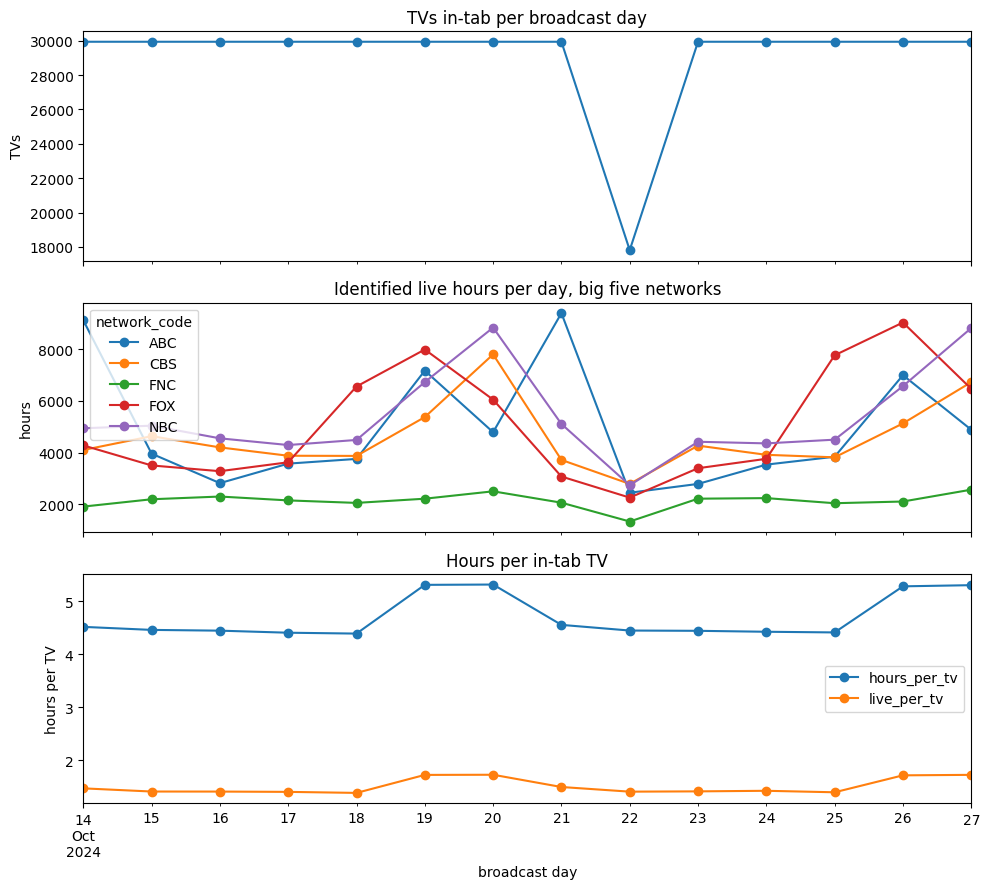

In [ ]:
big = live[live.network_code.isin(BIG)].pivot_table(index="bd", columns="network_code", values="hours", aggfunc="sum")
daily = pd.DataFrame({"intab": intab, "hours": ed.groupby("bd").hours.sum(), "live_hours": live.groupby("bd").hours.sum(),
                      "unknown_hours": ed[ed.session_type == "unknown"].groupby("bd").hours.sum()})
daily["hours_per_tv"] = daily.hours / daily.intab
daily["live_per_tv"] = daily.live_hours / daily.intab
daily["unknown_share"] = daily.unknown_hours / daily.hours

fig, ax = plt.subplots(3, 1, sharex=True, figsize=(10, 9))
daily.intab.plot(ax=ax[0], marker="o", title="TVs in-tab per broadcast day", ylabel="TVs")
big.plot(ax=ax[1], marker="o", title="Identified live hours per day, big five networks", ylabel="hours")
daily[["hours_per_tv", "live_per_tv"]].plot(ax=ax[2], marker="o", title="Hours per in-tab TV", ylabel="hours per TV",
                                         xlabel="broadcast day")
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [ ]:
spike_day, spike_net = big.stack().idxmax()
print("Biggest spike (date, network):", spike_day.date(), spike_net)
aired = programs[(programs.bd == spike_day) & (programs.network_code == spike_net)]
aired = aired.assign(tvs=[len(watchers(live, t, "tv_id")) for t in aired.itertuples()])
print(aired.nlargest(5, "tvs")[["program_name", "episode_name", "t0", "duration_min", "is_live", "tvs"]].to_string(index=False), "\n")

deviation = (daily[["intab", "hours_per_tv"]] / daily[["intab", "hours_per_tv"]].median() - 1).abs().max(axis=1)
print("Broken day (date):", deviation.idxmax().date())
print(daily.assign(weekday=daily.index.day_name()).round(3))

Biggest spike (date, network): 2024-10-21 ABC


                  program_name                              episode_name                  t0  duration_min  is_live  tvs
                  NFL Football                    NFL Football: BAL @ TB 2024-10-21 20:15:00           190     True 6130
Local / Syndicated Programming                                      None 2024-10-21 15:00:00           210    False  900
Local / Syndicated Programming                                      None 2024-10-21 19:00:00            60    False  718
Local / Syndicated Programming                                      None 2024-10-21 23:25:00            70    False  668
          Good Morning America Alessia Cara, Jenny Slate, Dr. Jill Biden 2024-10-21 07:00:00           120     True  651 

Broken day (date): 2024-10-22
            intab       hours  live_hours  unknown_hours  hours_per_tv  live_per_tv  unknown_share    weekday
bd                                                                                                           
2024-10-14  29940  135

**Answer:** what aired; what went wrong with the data; drop, fix or flag?

**Spike:** ABC on 2024-10-21, when Monday Night Football aired (NFL, Ravens at Buccaneers, 20:15, live) and reached 6,130 TVs,
a fifth of the footprint. **Broken day:** 2024-10-22, an ordinary Tuesday: in-tab TVs fall from 29,940 to 17,818 (−40%) and all
networks drop together, while hours per in-tab TV (4.45) and the unknown share stay normal, so about 12,000 TVs did not report and
the audience did not change. Unnoticed, that day's totals (hours, impressions) and any rating divided by all 29,940 TVs would be
40% too low, so **flag** the day: keep it, rate it on its own in-tab base (fair if the missing TVs are random, as the normal hours
per TV suggest) and leave it out of totals and trends.

## Task 5.1 — Sampling error vs bias

In [ ]:
se = ref[ref.program_name.str.contains("Football|Hannity|Unsellable")].copy()   # SNF is "NFL Football" in programs
p = se.hh_rating / 100
se["n_panel"] = se.bd.map(dwH.groupby("bd").size())                   # panel households in-tab that day
se["se_tv"] = 100 * (p * (1 - p) / se.n_tv) ** 0.5                    # rating points
se["se_panel"] = 100 * (p * (1 - p) / se.n_panel) ** 0.5
se["se_panel/se_tv"] = se.se_panel / se.se_tv
se["tv-ref"] = se.tv_rating - se.hh_rating
se["|bias|/se_tv"] = se["tv-ref"].abs() / se.se_tv
print(se[["program_name", "n_tv", "n_panel", "hh_rating", "se_tv", "se_panel", "se_panel/se_tv", "tv-ref", "|bias|/se_tv"]]
      .round({"hh_rating": 1, "se_tv": 2, "se_panel": 2, "se_panel/se_tv": 1, "tv-ref": 1, "|bias|/se_tv": 1}).to_string(index=False))

     program_name  n_tv  n_panel  hh_rating  se_tv  se_panel  se_panel/se_tv  tv-ref  |bias|/se_tv
     NFL Football 29940     3898       33.1   0.27      0.75             2.8   -11.9          43.7
          Hannity 29940     3867        2.3   0.09      0.24             2.8    -1.5          17.0
Unsellable Houses 29940     3867        3.7   0.11      0.30             2.8    -1.6          14.6


**Answer:** which error is bigger, and does more data shrink it?

The footprint's SE is 2.8 times smaller than the panel's, √(29,940 ÷ 3,867): 0.09 vs 0.24 rating points for Hannity, 0.11 vs 0.30
for Unsellable Houses. But the TVs' ratings miss the reference by 1.5–1.6 points for these two and by about 12 points for Sunday Night
Football (21.2 vs 33.1), 15 to 44 footprint SEs, so the bias is far bigger. More TVs shrink only the sampling error (as 1/√n), not the
bias, which comes from who is in the footprint and the one set it sees: a bigger convenience sample is just a more precise wrong number.

## Task 5.2 — Answer to the planner
**Answer:** 5-7 sentences.

From this feed I can give one number: 21.2% of the smart TVs in-tab (reporting) on October 27 watched at least a minute of Sunday Night Football live.
Please don't present it as the household rating: the currency rating is 33.1, so the feed is about 12 points (36%) too low, far more than
its ±0.3-point sampling error; for the presentation use 33.1.
Nor should it be used to compare telecasts before weighting: it is short of older homes, so it is 36% too low for the games but 64%
too low for Hannity.
The feed counts TV sets, not people, so it cannot say how many viewers or which demographics watched.
It sees one TV per home, not the other sets, and it cannot identify viewing in apps such as Peacock or anything it does not fingerprint
(40% of TV-on time is unknown). It also covers only homes that bought this brand and opted in, which are more affluent than the US, and
only 65% of its TVs match a household by IP. Before planning on it I would need it weighted to the US household profile and calibrated
against the currency (Lab 4), a persons conversion such as VPVH, and data-quality flags for days like October 22, when 40% of the TVs did not report.

## Bonus

In [ ]:
t = ref[ref.program_name.str.contains("Football")].iloc[0]                         # Sunday Night Football (NBC, Oct 27)
day = dw[dw.bd == t.bd].set_index("respondent_id")                                 # that day's weights
ages = viewer_attributes[viewer_attributes.attr_id == 300].set_index("respondent_id").value
a2554 = ages.index[ages.between(25, 54)]
persons = pan[pan.resp_type.isin(["R", "L"]) & pan.respondent_id.isin(a2554)]
viewers = day.weight.reindex(watchers(persons, t, "respondent_id")).sum()          # A25-54 persons who watched
viewing_hh = day.weight.reindex(watchers(panH, t, "respondent_id")).sum()          # households that watched
vpvh = viewers / viewing_hh
us_hh = day.weight[day.resp_type == "H"].sum()
us_a2554 = day.weight[day.index.isin(a2554)].sum()
print("VPVH A25-54:", round(vpvh, 3))
print("A25-54 rating (persons):", round(t.tv_rating * vpvh * us_hh / us_a2554, 1))
print("Panel's own A25-54 rating, for comparison:", round(100 * viewers / us_a2554, 1))

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
Panel's own A25-54 rating, for comparison: 17.8


**Answer:** what this assumes.

The estimate is 11.1 against the panel's own 17.8, 38% low: it assumes the TVs' household rating is the US one, so it inherits that
rating's shortfall (21.2 vs 33.1, 36%). It also assumes a footprint home that watched holds as many A25–54 viewers as a panel home that
watched (VPVH 0.513: same size, age mix and co-viewing), although footprint homes are more affluent than the US; and VPVH, being a panel
estimate, carries the panel's sampling error.